<h1> <center> House Price Prediction

<p> Dans ce notebook, on explore la régression linéaire simple sur un dataset 'California house pricing' 

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
X, y = fetch_california_housing(return_X_y= True, as_frame= True)
print('Les données ont été chargé avec succés!')

Les données ont été chargé avec succés!


In [3]:
# Convertir en data frame (optionel !!!)
df = X.copy()
df['target'] = y
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
# Les valeurs nulles
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
target        0
dtype: int64

In [7]:
# Les valeurs dupliquées
df.duplicated().sum()

0

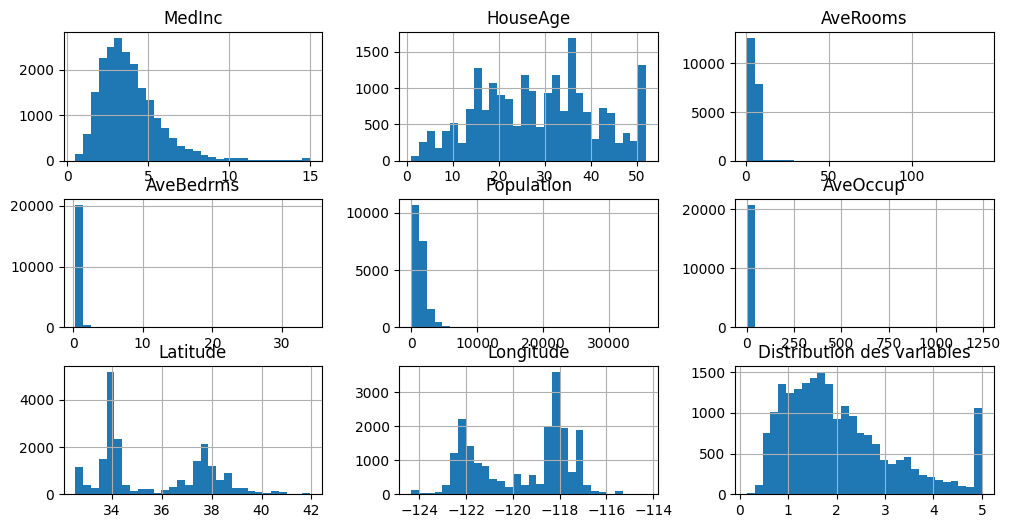

In [8]:
df.hist(figsize=(12,6), bins= 30)
plt.title('Distribution des variables')
plt.show()

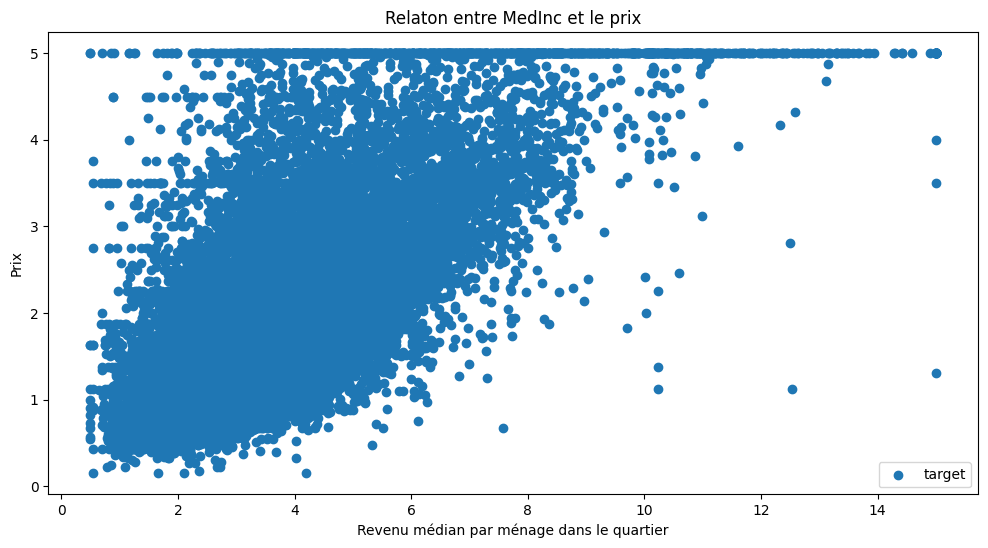

In [9]:
plt.figure(figsize= (12, 6))
plt.scatter(data= df, x= 'MedInc', y='target')
plt.title('Relaton entre MedInc et le prix')
plt.xlabel('Revenu médian par ménage dans le quartier')
plt.ylabel('Prix')
plt.legend()
plt.show()

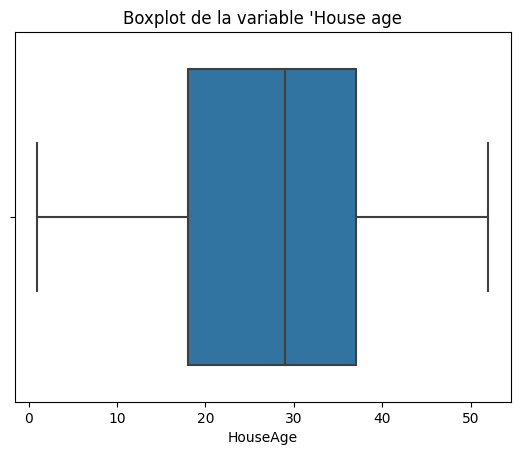

In [10]:
sns.boxplot(x= df['HouseAge'])
plt.title('Boxplot de la variable \'House age')
plt.show()

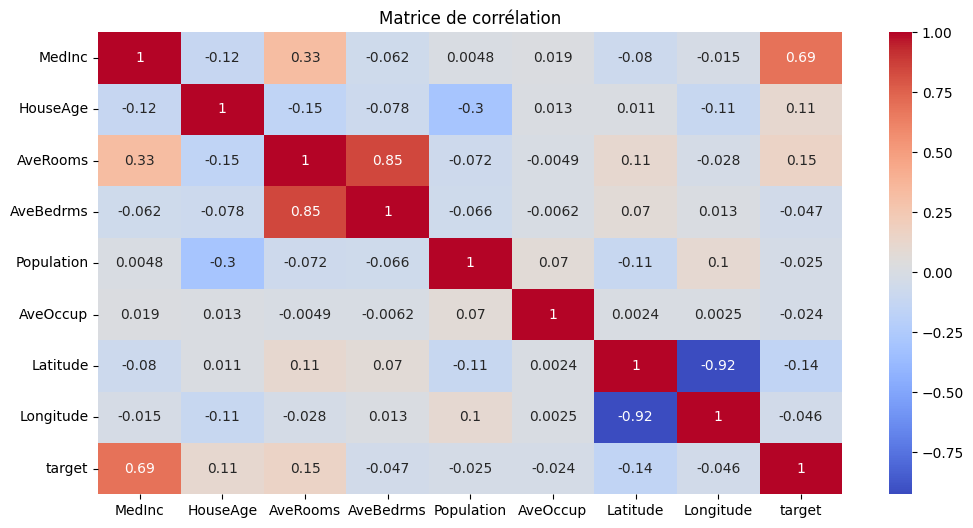

In [11]:
corr = df.corr(numeric_only= True)

plt.figure(figsize= (12, 6))
sns.heatmap(corr, annot= True, cmap= 'coolwarm')
plt.title('Matrice de corrélation')
plt.show()

In [12]:
# Pour entrainer un modéle de régression linéaire simple on choisit la variable avec une forte corrélation avec la variable cible 'target'
# Dans ce cas c'est la variable 'MedInc'

X = df[['MedInc']]
y = df[['target']]

In [13]:
# Division des données en train et test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train), len(X_test), len(y_test))

16512 16512 4128 4128


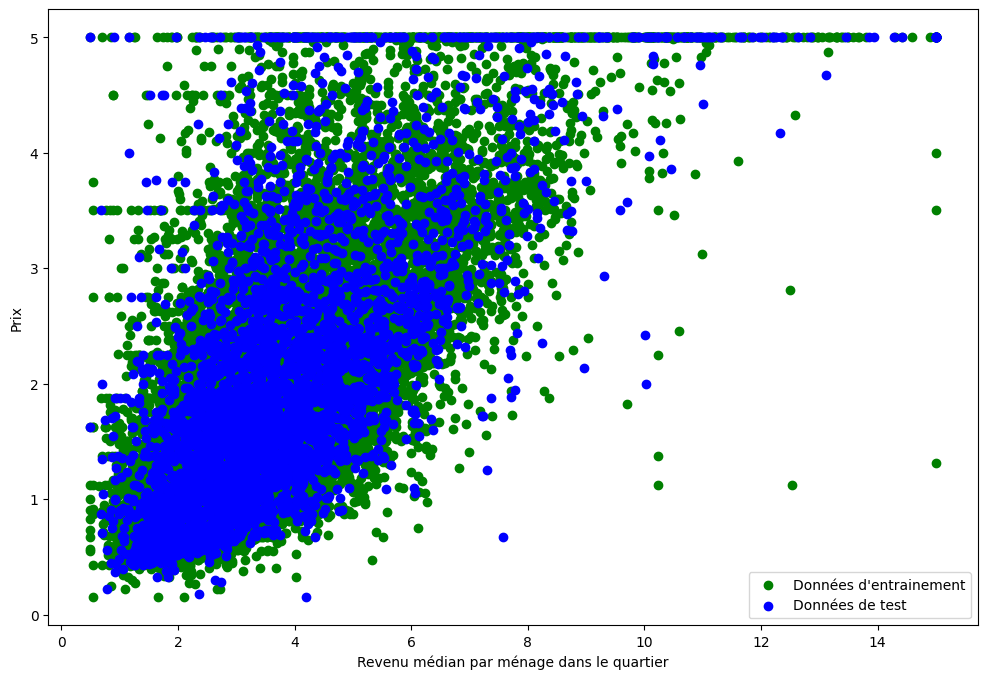

In [14]:
# Graphe des données d 'entrainement et de test
plt.figure(figsize=(12,8))
plt.scatter(X_train, y_train, color= 'green', label= 'Données d\'entrainement')
plt.scatter(X_test, y_test, color= 'blue', label= 'Données de test')
plt.xlabel('Revenu médian par ménage dans le quartier')
plt.ylabel('Prix')
plt.legend()
plt.show()

In [15]:
print('Avant standarisation : ', X_train.min(), X_train.max())

Avant standarisation :  MedInc    0.4999
dtype: float64 MedInc    15.0001
dtype: float64


In [16]:
scaler = StandardScaler()
scaler.fit_transform(X_train)


array([[-0.326196  ],
       [-0.03584338],
       [ 0.14470145],
       ...,
       [-0.49697313],
       [ 0.96545045],
       [-0.68544764]])

In [17]:
print('Après standarisation : ', X_train.min(), y_train.min())

Après standarisation :  MedInc    0.4999
dtype: float64 target    0.14999
dtype: float64


In [18]:
scaler.transform(X_test)

array([[-1.15508475],
       [-0.70865905],
       [-0.21040155],
       ...,
       [ 2.80902421],
       [-0.57542978],
       [-0.17259111]])

In [19]:
# initialisation du modéle
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [20]:
# Faire une prédiction
y_pred = lr.predict(X_test)

In [21]:
print("Les paramétres de la droite de régression sont: ")
print("La pente est : ", lr.coef_[0])
print("L'intercept est :", lr.intercept_)

Les paramétres de la droite de régression sont: 
La pente est :  [0.41933849]
L'intercept est : [0.44459729]


In [22]:
# Mean squared erro
mse = mean_squared_error(y_test, y_pred)
print("Mean squared error mse = ", mse)

Mean squared error mse =  0.7091157771765548


In [23]:
# R2 score
r2 = r2_score(y_test, y_pred)
print("La valeur de r2 score est : ", r2)

La valeur de r2 score est :  0.45885918903846656


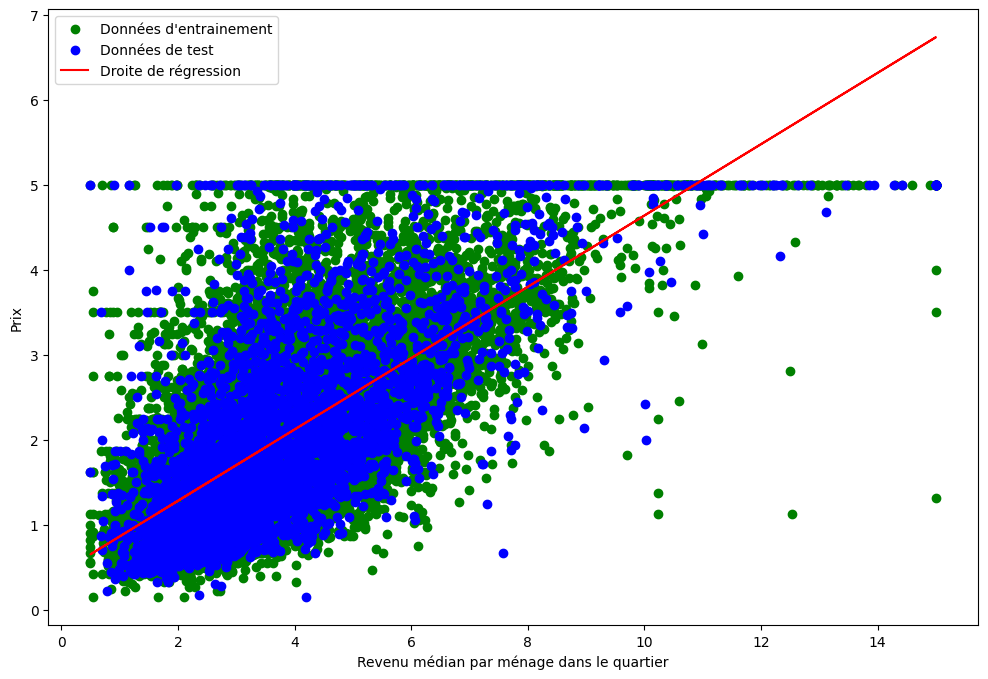

In [24]:
# Graphe des données avec la droite de régression
plt.figure(figsize=(12,8))
plt.scatter(X_train, y_train, color= 'green', label= 'Données d\'entrainement')
plt.scatter(X_test, y_test, color= 'blue', label= 'Données de test')
plt.plot(X_test, y_pred, color= 'red', label= 'Droite de régression')
plt.xlabel('Revenu médian par ménage dans le quartier')
plt.ylabel('Prix')
plt.legend()
plt.show()

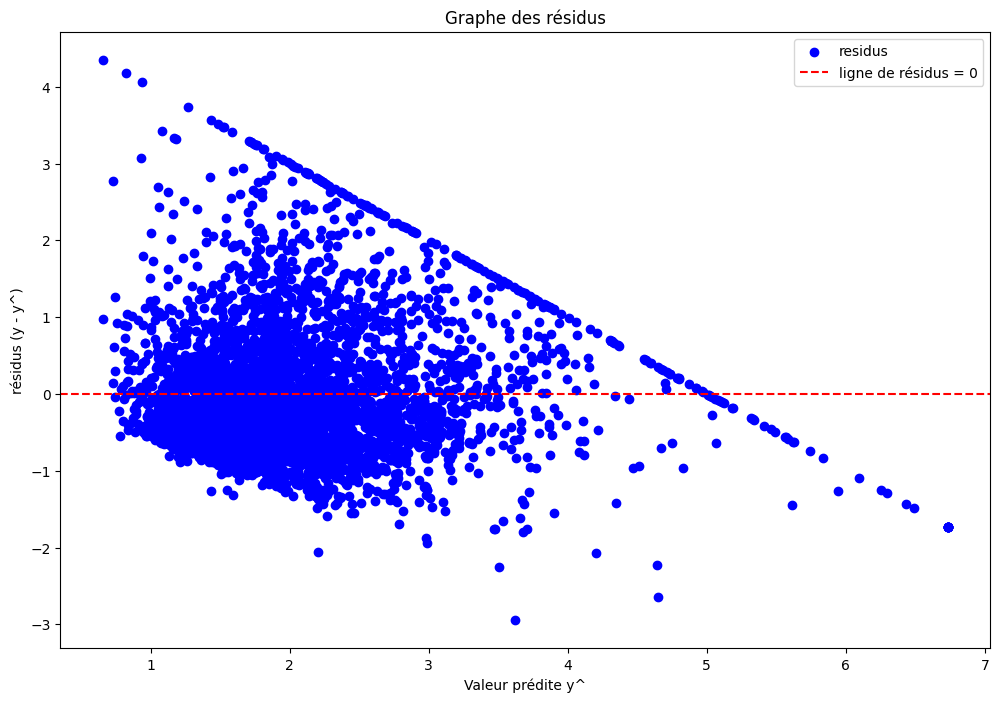

In [25]:
# Graphe des résidus
residual = y_test - y_pred
plt.figure(figsize= (12,8))
plt.scatter(y_pred, residual, color = 'blue', label= 'residus')
plt.axhline(y= 0, color= 'red', label= 'ligne de résidus = 0', linestyle= '--')
plt.title('Graphe des résidus')
plt.xlabel('Valeur prédite y^')
plt.ylabel('résidus (y - y^)')
plt.legend()
plt.show()

In [26]:
import joblib
joblib.dump(lr, "model.joblib")


['model.joblib']

<h1><center> FIN